# EOG / EMG data exploration (EDA) and model training

Everything that *studies* the data lives here; `EOG_Detection.ipynb` only runs the finished detector.

* **Part 1 (sections 1-10): the data itself.** Signal, quality, spectrum, differences between people, the labels. No detector, no model.
* **Part 2 (sections 11-12): the eye events and the model.** Detect eye events, see how the features change when the driver feels drowsy, train the model from scratch, test it on people it has never seen and save it for `EOG_Detection.ipynb`.

It works for any recording with one or more signal channels and (optionally) time marks such as "driver pressed the drowsy button". **To explore another dataset, change only the settings cell and `load_recording` in section 1**; every later cell reads the data through those. (Part 2 additionally assumes the marks mean "I feel drowsy".)

## 1. Settings and loading

In [1]:
import os, urllib.request

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pyedflib
from scipy import signal

# ---- The settings cell: the only thing that depends on the dataset ----
DATASET = {
    "name": "DD-Database (Zenodo 8284057, CC0)",
    "folder": "data/dd_database",
    "url": "https://zenodo.org/api/records/8284057/files/{}/content",
    "recordings": ["01M_1", "02F_1", "03F_1", "04M_1", "05M_1", "06M_1", "07F_1"],   # trial 1 of subjects 1-7
    "fs": 128,                                      # sampling rate (Hz)
    "eye_channels": ("LOC-Ref", "ROC-Ref"),         # electrodes at the outer corners of the eyes; their difference is the eye signal
    "mains_hz": 50,                                 # power-line frequency where it was recorded (50 or 60)
}
FS = DATASET["fs"]

**Dataset: DD-Database** (Drivers Drowsiness Database, Universidad Nacional de San Juan, [Zenodo](https://zenodo.org/records/8284057), CC0). 10 volunteers drove a **night-time driving simulator** for 2 hours (twice), partly sleep-deprived, and pressed a button whenever they **felt drowsy**. Recorded: 2 EOG channels (LOC, ROC), 4 EEG, 1 ECG, 128 Hz, raw. Only trial 1 of subjects 1-7 is used (7 files, 91 MB); subjects 8-10 pressed the button only 2-8 times in total.

In [2]:
def download():
    os.makedirs(DATASET["folder"], exist_ok=True)
    for name in DATASET["recordings"]:
        for suffix in ("", "_annotations"):
            path = f"{DATASET['folder']}/{name}{suffix}.edf"
            if not os.path.exists(path):
                print("downloading", path)
                urllib.request.urlretrieve(DATASET["url"].format(f"{name}{suffix}.edf"), path)


def load_recording(name):
    """One recording -> {"signals": {channel name: microvolts}, "marks": times (s) of the driver's 'I feel drowsy' button presses}.
    For another dataset, rewrite this function (and `download`); nothing else in the notebook changes."""
    r = pyedflib.EdfReader(f"{DATASET['folder']}/{name}.edf")
    signals = {label: r.readSignal(i) for i, label in enumerate(r.getSignalLabels())}
    r.close()
    a = pyedflib.EdfReader(f"{DATASET['folder']}/{name}_annotations.edf")
    marks = np.array(a.readAnnotations()[0])
    a.close()
    return {"signals": signals, "marks": marks[(marks > 30) & (marks < 7000)]}   # the marks at about 10 s and 7220 s are start / end markers


def eye_signal(rec):
    """The eye channel: the difference of the two eye electrodes (or the single channel if only one is given)."""
    a, b = DATASET["eye_channels"]
    return rec["signals"][a] - rec["signals"][b] if b else rec["signals"][a]


download()
data = {name: load_recording(name) for name in DATASET["recordings"]}

## 2. What is in the files?

In [3]:
pd.DataFrame({name: {"length (min)": len(eye_signal(rec)) / FS / 60, "channels": len(rec["signals"]),
                     "marks": len(rec["marks"]), "first mark (min)": rec["marks"][0] / 60 if len(rec["marks"]) else np.nan}
              for name, rec in data.items()}).T.round(1)

,length (min),channels,marks,first mark (min)
01M_1,121.8,7.0,23.0,25.2
02F_1,123.0,7.0,34.0,3.8
03F_1,121.8,7.0,81.0,13.2
04M_1,115.5,7.0,35.0,6.6
05M_1,120.8,7.0,23.0,18.4
06M_1,120.2,7.0,33.0,12.9
07F_1,121.5,7.0,88.0,13.0


In [4]:
print("channels:", list(next(iter(data.values()))["signals"]))

channels: ['O1-Ref', 'O2-Ref', 'C3-Ref', 'C4-Ref', 'LOC-Ref', 'ROC-Ref', 'EKG']


## 3. Is the signal usable? (quality per recording)
Four quick checks on the eye signal: **missing values**, **flat stretches** (1 s windows that barely move: electrode off or amplifier stuck), **clipping** (samples sitting at the extreme value: amplifier saturated) and the **correlation of the two eye channels** (a good pair mirrors each other).

In [5]:
def quality(rec):
    x = eye_signal(rec)
    windows = x[:len(x) // FS * FS].reshape(-1, FS)
    a, b = DATASET["eye_channels"]
    return {"missing (%)": 100 * np.isnan(x).mean(),
            "flat seconds (%)": 100 * np.mean(windows.std(axis=1) < 0.1),
            "at min or max (%)": 100 * np.mean((x == x.max()) | (x == x.min())),
            "spread, std (uV)": np.nanstd(x),
            "eye channels correlation": np.corrcoef(rec["signals"][a], rec["signals"][b])[0, 1] if b else np.nan}

quality_table = pd.DataFrame({name: quality(rec) for name, rec in data.items()}).T
quality_table.round(2)

,missing (%),flat seconds (%),at min or max (%),"spread, std (uV)",eye channels correlation
01M_1,0.0,0.03,0.0,61.91,-0.80
02F_1,0.0,0.03,0.0,107.44,-0.70
03F_1,0.0,0.00,0.0,47.72,-0.45
04M_1,0.0,0.03,0.0,47.82,-0.75
05M_1,0.0,0.03,0.0,44.11,-0.70
06M_1,0.0,0.07,0.0,51.27,-0.41
07F_1,0.0,0.00,0.0,48.48,-0.82


## 4. The raw signal
Thirty seconds of every channel of one recording. EOG channels show fast spikes (blinks, eye movements), EEG channels fast small waves, the ECG regular beats.

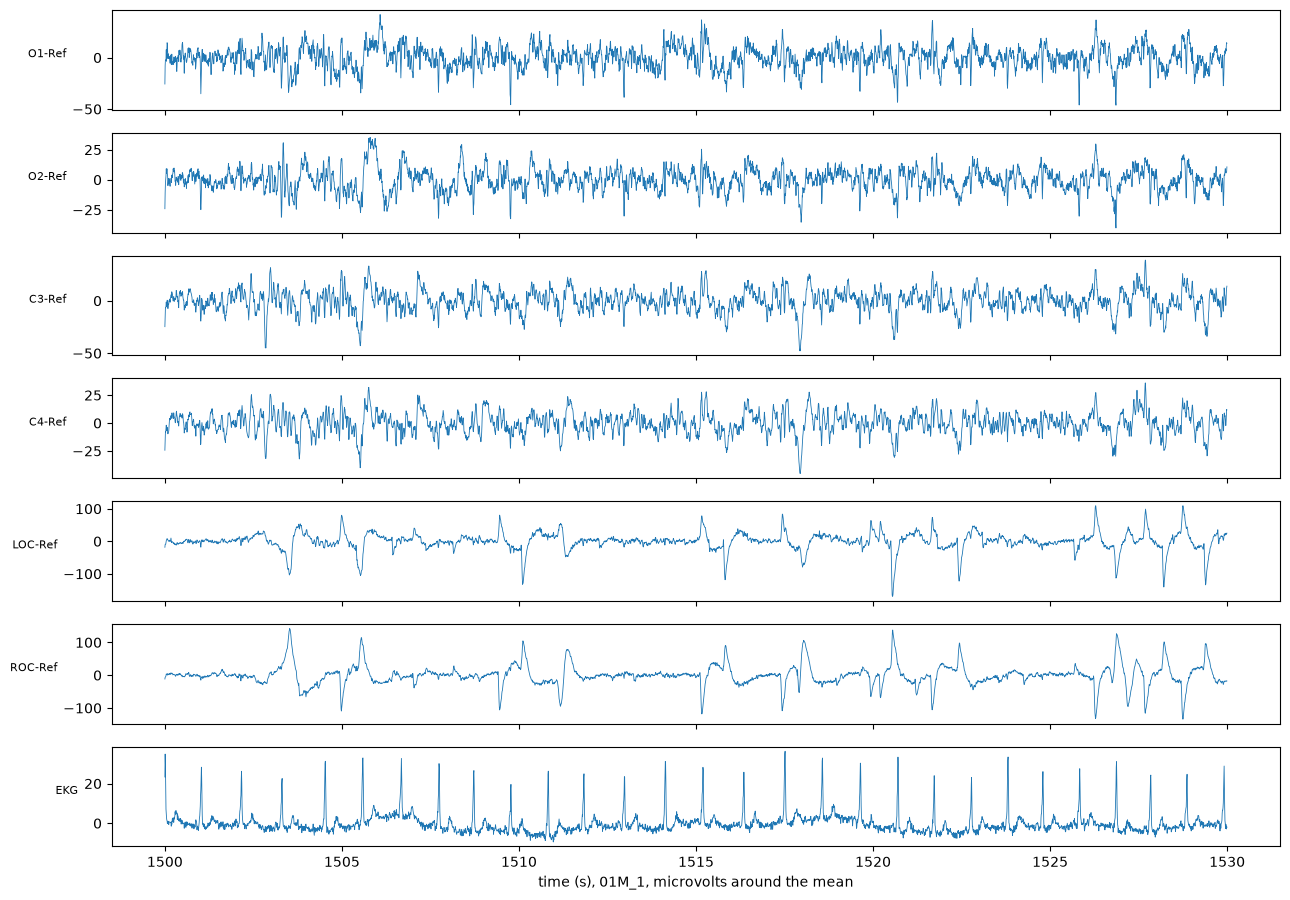

In [6]:
name = DATASET["recordings"][0]
signals = data[name]["signals"]
T0 = 1500                                                    # start of the excerpt (s)
t = np.arange(T0 * FS, (T0 + 30) * FS) / FS
fig, axes = plt.subplots(len(signals), 1, figsize=(13, 1.3 * len(signals)), sharex=True)
for ax, (label, x) in zip(axes, signals.items()):
    ax.plot(t, x[T0 * FS:(T0 + 30) * FS] - np.mean(x[T0 * FS:(T0 + 30) * FS]), lw=0.6); ax.set_ylabel(label, rotation=0, ha="right", fontsize=8)
axes[-1].set_xlabel(f"time (s), {name}, microvolts around the mean")
plt.tight_layout(); plt.show()

## 5. The two eye channels
The electrodes sit just below and above the outer corners of the two eyes. When the eyes move or blink, one goes up while the other goes down, so the channels are **mirror images** (negative correlation in the table above) and their **difference** is the clean "eye signal". Noise that hits both electrodes equally is cancelled.

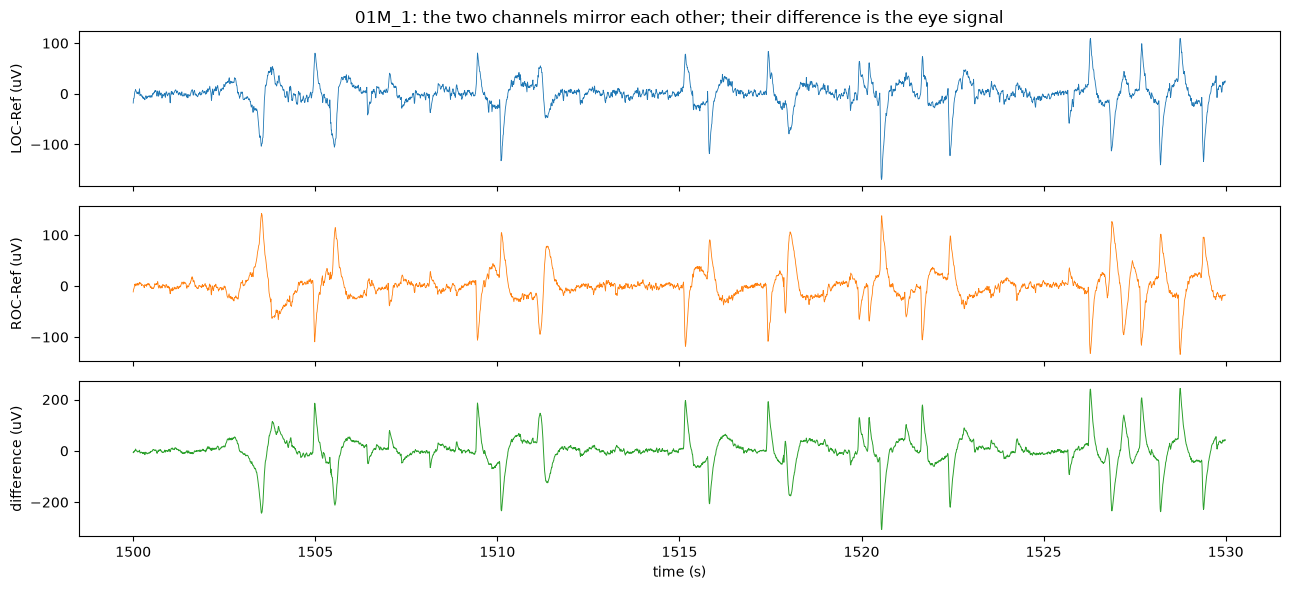

In [7]:
a, b = DATASET["eye_channels"]
sl = slice(T0 * FS, (T0 + 30) * FS)
fig, axes = plt.subplots(3, 1, figsize=(13, 6), sharex=True)
axes[0].plot(t, signals[a][sl] - signals[a][sl].mean(), lw=0.6); axes[0].set_ylabel(a + " (uV)")
axes[1].plot(t, signals[b][sl] - signals[b][sl].mean(), lw=0.6, color="tab:orange"); axes[1].set_ylabel(b + " (uV)")
axes[2].plot(t, eye_signal(data[name])[sl], lw=0.7, color="tab:green"); axes[2].set_ylabel("difference (uV)"); axes[2].set_xlabel("time (s)")
axes[0].set_title(f"{name}: the two channels mirror each other; their difference is the eye signal")
plt.tight_layout(); plt.show()

## 6. Where is the signal's energy? (frequency content)
Power spectrum of the eye signal for every recording. Eye events live below about 10 Hz; the power-line hum shows as a thin spike at the mains frequency (grey line). The detector later keeps only 0.1-20 Hz, so the hum and the fast EEG/muscle noise are removed.

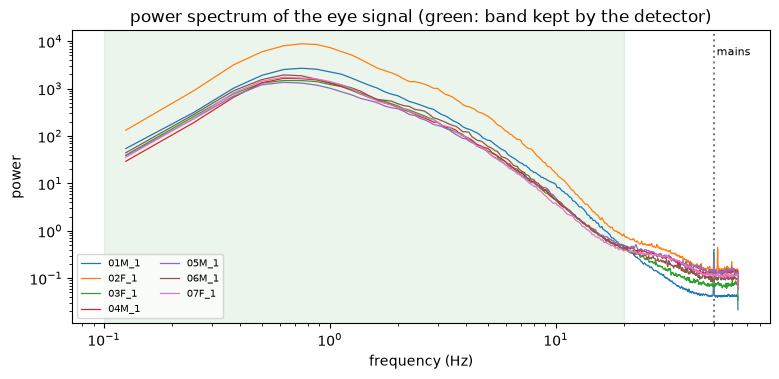

In [8]:
fig, ax = plt.subplots(figsize=(9, 3.8))
for name_, rec in data.items():
    f, pxx = signal.welch(eye_signal(rec) - np.mean(eye_signal(rec)), fs=FS, nperseg=FS * 8)
    ax.loglog(f[1:], pxx[1:], lw=0.9, label=name_)
ax.axvline(DATASET["mains_hz"], color="grey", ls=":"); ax.text(DATASET["mains_hz"] * 1.03, ax.get_ylim()[1] * 0.3, "mains", fontsize=8)
ax.axvspan(0.1, 20, alpha=0.08, color="green"); ax.set_xlabel("frequency (Hz)"); ax.set_ylabel("power"); ax.legend(fontsize=7, ncol=2)
ax.set_title("power spectrum of the eye signal (green: band kept by the detector)")
plt.show()

## 7. How different are the people?
The same eye movement gives a different number of microvolts for every person (skin, electrode contact, placement), and would for a different amplifier gain too. Below: the **typical size** of the signal (robust spread, 0.1-20 Hz) and its **largest swings** (99th percentile) per recording.
If these differ a lot, a fixed limit like "an event is above 200 uV" works for one person and fails for another. The detector therefore measures everything in units of the signal's own noise.

,"typical size, MAD (uV)","largest swings, 99th percentile (uV)"
01M_1,26.2,234.8
02F_1,43.6,427.7
03F_1,21.9,188.5
04M_1,23.0,187.8
05M_1,22.0,170.8
06M_1,18.0,204.5
07F_1,27.7,183.0


typical size differs by a factor 2.4 between the smallest and largest person


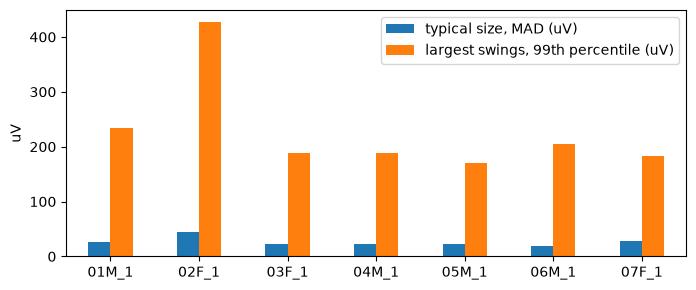

In [9]:
sos = signal.butter(2, [0.1, 20], btype="band", fs=FS, output="sos")
filtered = {n: signal.sosfilt(sos, eye_signal(rec)) for n, rec in data.items()}
scale = pd.DataFrame({n: {"typical size, MAD (uV)": 1.4826 * np.median(np.abs(y - np.median(y))),
                          "largest swings, 99th percentile (uV)": np.percentile(np.abs(y), 99)} for n, y in filtered.items()}).T
display(scale.round(1))
print(f"typical size differs by a factor {scale.iloc[:, 0].max() / scale.iloc[:, 0].min():.1f} between the smallest and largest person")
scale.plot.bar(figsize=(8, 3.2), rot=0); plt.ylabel("uV"); plt.show()

## 8. Slow drift
The median of the raw eye signal per minute through the session. A slow drift (electrode polarisation, sweat, posture) must not be mistaken for eye activity, so the detector removes everything below 0.1 Hz.

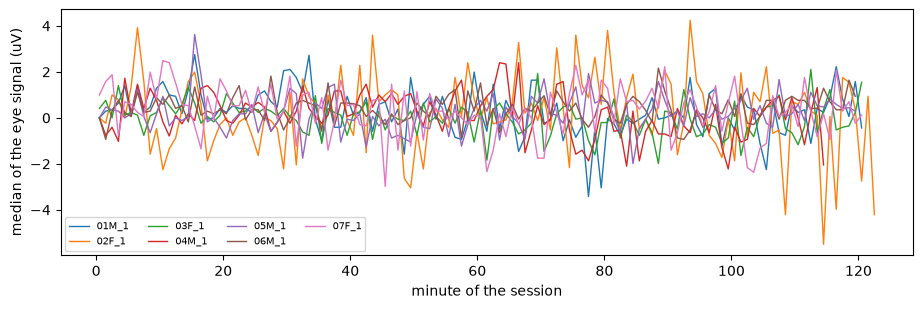

In [10]:
fig, ax = plt.subplots(figsize=(11, 3.2))
for n, rec in data.items():
    x = eye_signal(rec); m = len(x) // (FS * 60)
    ax.plot(np.arange(m) + 0.5, np.median(x[:m * FS * 60].reshape(m, -1), axis=1), lw=1, label=n)
ax.set_xlabel("minute of the session"); ax.set_ylabel("median of the eye signal (uV)"); ax.legend(fontsize=7, ncol=4)
plt.show()

## 9. The marks (button presses)
Each tick is one press of "I feel drowsy". They are the only labels in this dataset, so how they are spread decides what can be learned. People differ in how often they report, and a driver may be drowsy for a while before pressing, or press and then recover, so the labels are **noisy**.

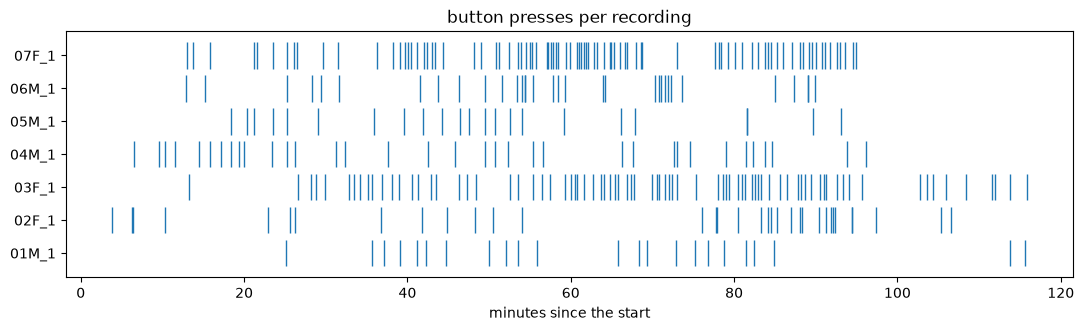

presses in the first hour: 48%, in the second hour: 52%
gap between two presses: median 62 s, shortest 1 s, longest 29 min


In [11]:
fig, ax = plt.subplots(figsize=(13, 3.2))
for i, (n, rec) in enumerate(data.items()):
    ax.vlines(rec["marks"] / 60, i + 0.1, i + 0.9, lw=1)
ax.set_yticks(np.arange(len(data)) + 0.5); ax.set_yticklabels(list(data)); ax.set_xlabel("minutes since the start"); ax.set_title("button presses per recording")
plt.show()
all_marks = np.concatenate([rec["marks"] for rec in data.values()]) / 60
gaps = np.concatenate([np.diff(rec["marks"]) for rec in data.values() if len(rec["marks"]) > 1])
print(f"presses in the first hour: {np.mean(all_marks < 60):.0%}, in the second hour: {np.mean(all_marks >= 60):.0%}")
print(f"gap between two presses: median {np.median(gaps):.0f} s, shortest {gaps.min():.0f} s, longest {gaps.max() / 60:.0f} min")

## 10. Insights
1. **The data is clean.** No missing values, no clipping, and almost no flat seconds (at most 0.07% of the time) in any of the 7 recordings.
2. **The two eye channels mirror each other** (correlation -0.4 to -0.8, section 3), so the difference is the right eye signal. Two recordings (03F_1, 06M_1) are only about -0.4: their electrodes picked up more that is not eye movement, so expect them to be harder.
3. **Eye events are slow and low-frequency**: most power lies below 10 Hz, thousands of times above the 30-60 Hz band. The 50 Hz hum is clear in one recording (01M_1, about 8 times its neighbouring frequencies) but barely visible in the others after the subtraction, so a notch filter is harmless but not critical here.
4. **People differ in scale**: the typical signal size differs by a factor of 2.4 and the largest swings by 2.5 between the smallest and largest recording (02F_1 is the largest). A fixed microvolt limit would suit one person and not another, which is why the detector uses the signal's own noise level.
5. **Drift is small in the eye signal**: the per-minute median moves by only about 5 uV, against a typical signal size of 20-45 uV. It is still removed (high-pass 0.1 Hz) as it would grow with a bad electrode.
6. **Labels are the weak point**: 23 to 88 presses per recording, spread evenly over both hours (48% / 52%), with a median gap of about a minute but gaps from 1 s to 29 min. Subjects 3 and 7 press three to four times as often as subjects 1 and 5. Any drowsiness model trained on these labels inherits that noise.

# Part 2. Eye events, features and the model

The detector, the monitor and the model class are in `drowsiness/bio/eye_events.py` (shared with `EOG_Detection.ipynb`).

## 11. Eye events and drowsiness features

In [12]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix, roc_auc_score, roc_curve
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

from drowsiness.bio.eye_events import BASELINE_S, CALIBRATE_S, FEATURES, WINDOW_S, DrowsinessMonitor, EyeEventStream, LinearModel

MODEL_PATH = "models/eog_drowsiness_model.json"
STEP_S = 30                                                  # a new score every 30 s
eye = {name: (eye_signal(rec), rec["marks"]) for name, rec in data.items()}       # (eye signal, button presses)

**Eye events.** An eye event is a short, fast deflection of the eye signal (a blink or a quick eye movement); slow drifts are not events. The detector is described in its file. **Visual check** on subject 1: red = detected events. Left: a busy minute, right: a quiet one. The marks sit on the real fast deflections, and the slow wobbles between them are left alone.

3201 events in 122 minutes (26.3 per minute); noise level learned: 12.5 uV


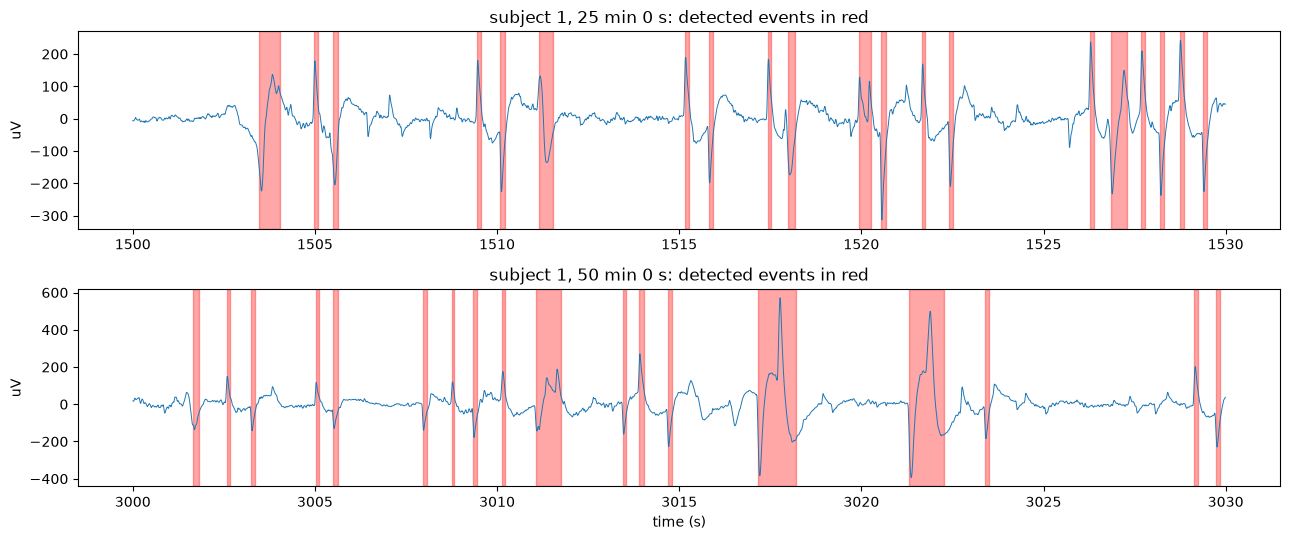

In [13]:
x, press = eye["01M_1"]
t = np.arange(len(x)) / FS
stream = EyeEventStream(FS, "eog")
stream.process(t, x)
events = stream.detector.events
print(f"{len(events)} events in {t[-1] / 60:.0f} minutes ({len(events) / (t[-1] / 60):.1f} per minute); noise level learned: {stream.detector.sigma_cal:.1f} uV")

fig, axes = plt.subplots(2, 1, figsize=(13, 5.5))
band = signal.sosfilt(signal.butter(2, [0.1, 20], btype="band", fs=FS, output="sos"), x)
for ax, t0 in zip(axes, (1500, 3000)):
    m = (t >= t0) & (t < t0 + 30)
    ax.plot(t[m], band[m], lw=0.7)
    for e in events:
        if t0 <= e["start"] < t0 + 30:
            ax.axvspan(e["start"], e["end"], color="r", alpha=0.35)
    ax.set_ylabel("uV"); ax.set_title(f"subject 1, {t0 // 60} min {t0 % 60} s: detected events in red")
axes[1].set_xlabel("time (s)")
plt.tight_layout(); plt.show()

### Replay every recording through the monitor, as a live stream
Each recording is fed one second at a time, like a sensor. Every 30 s the monitor's features are stored (no model yet). The labels:
* **drowsy** = the driver pressed the button inside the window or in the 60 s after it;
* **alert** = no press from 3 minutes before to 3 minutes after the window;
* windows in between are ambiguous and are not used for training or scoring accuracy.

In [14]:
def label(press, t_end):
    after = press[press >= t_end - WINDOW_S] - t_end                       # presses inside the window or later
    if len(after) and after.min() <= 60:
        return 1
    return 0 if np.abs(press - (t_end - WINDOW_S / 2)).min() > 180 else -1


rows, events_of = [], {}
for name, (diff, press) in eye.items():
    monitor = DrowsinessMonitor(None, FS, "eog")
    for i in range(0, len(diff), FS):                                      # one second at a time
        t_chunk = np.arange(i, min(i + FS, len(diff))) / FS
        out = monitor.update(t_chunk, diff[i:i + FS])
        t_end = t_chunk[-1] + 1 / FS
        if abs(t_end % STEP_S) < 1e-6 and out["raw"]["status"] == "ok":
            rows.append({"rec": name, "subj": name[:2], "t_end": t_end, "confidence": out["confidence"], "label": label(press, t_end),
                         **out["raw"]["features_vs_baseline"]})
    events_of[name] = monitor.stream.detector.events
table = pd.DataFrame(rows)
print(f"{len(table)} windows from {table.subj.nunique()} people; mean confidence {table.confidence.mean():.2f}")
labelled = table[(table.label >= 0) & (table.confidence >= 0.5)].reset_index(drop=True)
print(f"labelled windows: {len(labelled)}  (drowsy {int(labelled.label.sum())}, alert {int((1 - labelled.label).sum())})")

1582 windows from 7 people; mean confidence 0.92
labelled windows: 1316  (drowsy 857, alert 459)


### What does drowsy look like in the features?
**Eye events become rarer when the driver feels drowsy.** Below: the event rate relative to the person's own start, grouped by how close the next button press is. If the pattern is real, the rate should be lower near presses.

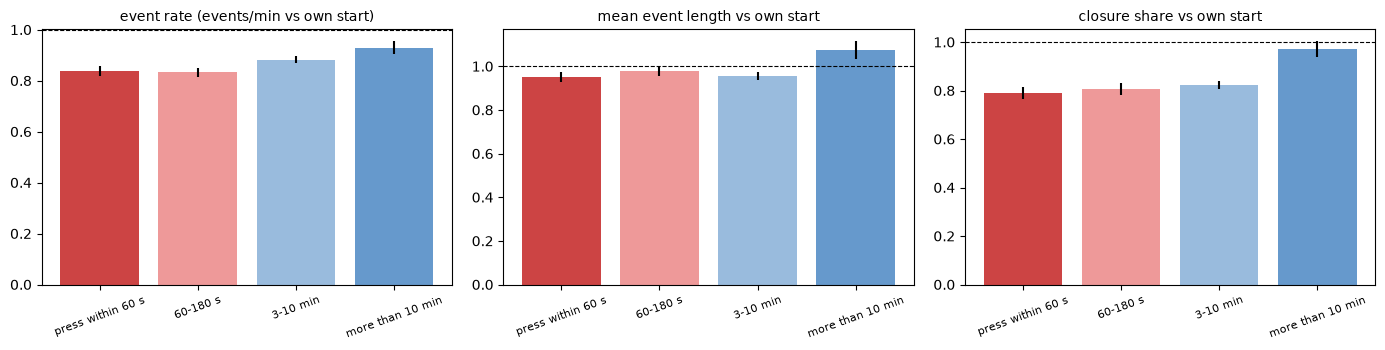

In [15]:
t_next = []
for _, row in table.iterrows():
    press = eye[row.rec][1]
    ahead = press[press >= row.t_end - WINDOW_S] - row.t_end
    t_next.append(ahead.min() if len(ahead) else np.inf)
table["to_next_press"] = t_next
bins = [(-1, 60, "press within 60 s"), (60, 180, "60-180 s"), (180, 600, "3-10 min"), (600, 1e9, "more than 10 min")]
fig, axes = plt.subplots(1, 3, figsize=(14, 3.6))
for ax, (feature, title) in zip(axes, [("rate", "event rate (events/min vs own start)"), ("width", "mean event length vs own start"), ("share", "closure share vs own start")]):
    means = [table[(table.to_next_press > a) & (table.to_next_press <= b)][feature].mean() for a, b, _ in bins]
    sem = [table[(table.to_next_press > a) & (table.to_next_press <= b)][feature].sem() for a, b, _ in bins]
    ax.bar([lab for _, _, lab in bins], means, yerr=sem, color=["#c44", "#e99", "#9bd", "#69c"]); ax.axhline(1, color="k", lw=0.8, ls="--")
    ax.set_title(title, fontsize=10); ax.tick_params(axis="x", labelsize=8, rotation=20)
plt.tight_layout(); plt.show()

**How informative is each feature on its own?** AUC for telling "drowsy" from "alert" windows, per person (0.5 = no information, 1 = perfect). A value **below** 0.5 means the feature goes **down** when drowsy.

,mean AUC,worst person,best person
rate,0.34,0.25,0.41
width,0.52,0.38,0.65
share,0.39,0.31,0.51
ivcv,0.56,0.48,0.63


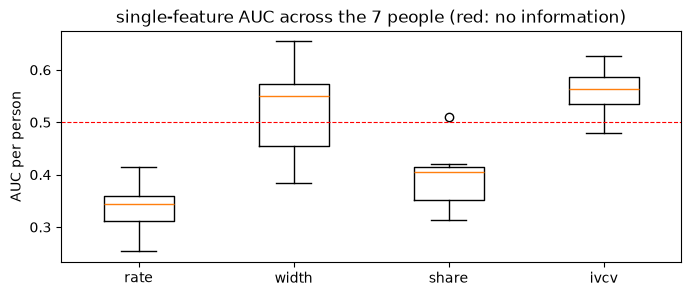

In [16]:
single = {f: [roc_auc_score(g.label, g[f]) for _, g in labelled.groupby("subj") if g.label.nunique() == 2] for f in FEATURES}
single_table = pd.DataFrame({f: {"mean AUC": np.mean(v), "worst person": np.min(v), "best person": np.max(v)} for f, v in single.items()}).T
display(single_table.round(2))
fig, ax = plt.subplots(figsize=(8, 3))
ax.boxplot(list(single.values()), tick_labels=list(single)); ax.axhline(0.5, color="r", ls="--", lw=0.8); ax.set_ylabel("AUC per person"); ax.set_title("single-feature AUC across the 7 people (red: no information)")
plt.show()

**Insights from the exploration**
1. **Eye activity goes down when the driver feels drowsy.** Relative to the person's own start, the event rate and the closure share are lowest in the windows right before a button press and highest when no press is near (see the bars). The single-feature AUCs agree: **rate and closure share are well below 0.5**, meaning they are *lower* in drowsy windows. That matches the literature: drowsy people blink and look around less.
2. **Event length alone says almost nothing** (AUC close to 0.5), and **irregularity** is only slightly informative. No single feature is strong, which is why a combination is used.
3. **People differ a lot**: the worst and best person differ widely for every feature. Using each person's own baseline removes part of this, not all.
4. The labels are the drivers' own button presses, so even a perfect detector could not score perfectly: part of the "error" is noise in the labels.

## 12. Is there a pretrained model? No, so one is trained from scratch
Checked first, as preferred:
* **`joncarter/wav2sleep-eog`** (Hugging Face, MIT) is the closest: it takes the same two EOG channels at about the same rate. But it classifies **sleep stages** from whole-night recordings with a non-causal network, not driver drowsiness, it cannot run live, it cannot take an **EMG** signal, and its code is not on PyPI (it would mean running an unvetted GitHub repository). Not suitable.
* No pretrained model for EMG or EOG drowsiness exists on Hugging Face (searches for EOG, EMG, blink, drowsiness).

So a **logistic regression** is trained on four explainable features per 120 s window. It is small enough to read, and it can be checked.

### Training and honest evaluation (leave one person out)
A model is trained on 6 people and tested on the 7th, seven times, so **every score below is for a person the model has never seen**. Mean and spread over people are reported, plus recall for each class and the confusion matrix, as accuracy alone would hide a model that favours one class.

In [17]:
def fit(df):
    pipe = make_pipeline(StandardScaler(), LogisticRegression(class_weight="balanced", C=0.3)).fit(df[FEATURES], df.label)
    scaler, clf = pipe[0], pipe[1]
    return LinearModel(scaler.mean_, scaler.scale_, clf.coef_[0], clf.intercept_[0])


per_person, oof = {}, {}
for person in labelled.subj.unique():
    model = fit(labelled[labelled.subj != person])
    test = labelled[labelled.subj == person].copy()
    test["score"] = [model.score(r) for _, r in test.iterrows()]
    oof[person] = test
    fpr, tpr, _ = roc_curve(test.label, test.score)
    per_person[person] = {"AUC": roc_auc_score(test.label, test.score), "fpr": fpr, "tpr": tpr,
                          "drowsy windows": int(test.label.sum()), "alert windows": int((1 - test.label).sum())}
result = pd.concat(oof.values())
aucs = np.array([v["AUC"] for v in per_person.values()])
print(f"AUC on unseen people: mean {aucs.mean():.2f}, spread (std) {aucs.std():.2f}, worst {aucs.min():.2f}, best {aucs.max():.2f}")
pd.DataFrame({p: {k: v for k, v in d.items() if k not in ("fpr", "tpr")} for p, d in per_person.items()}).T.round(2)

AUC on unseen people: mean 0.65, spread (std) 0.06, worst 0.57, best 0.74


,AUC,drowsy windows,alert windows
01,0.58,99.0,95.0
02,0.63,106.0,77.0
03,0.57,178.0,28.0
04,0.63,134.0,42.0
05,0.67,100.0,86.0
06,0.69,89.0,78.0
07,0.74,151.0,53.0


all unseen windows pooled: accuracy 0.63, recall of ALERT 0.67, recall of DROWSY 0.60


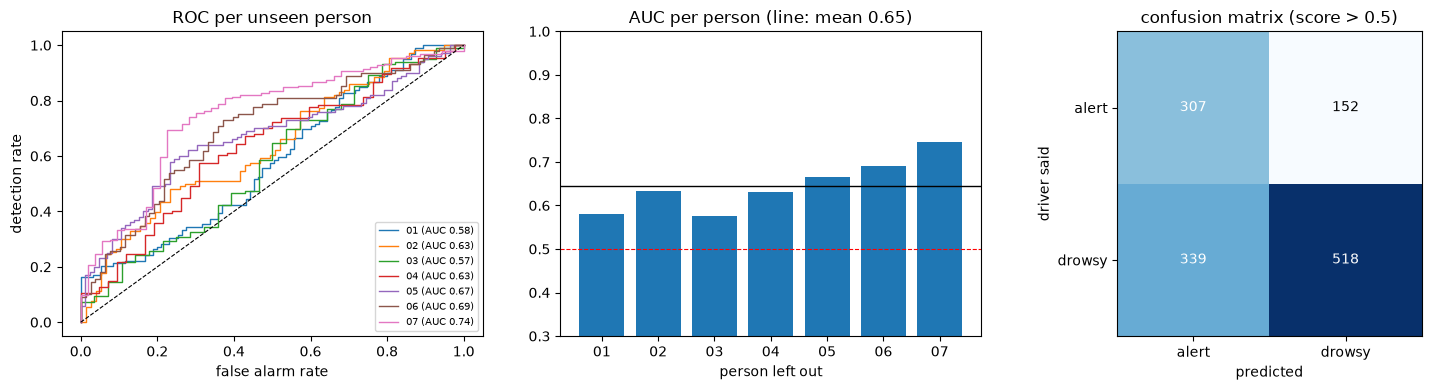

In [18]:
pred = (result.score > 0.5).astype(int)
cm = confusion_matrix(result.label, pred)
recall_alert, recall_drowsy = cm[0, 0] / cm[0].sum(), cm[1, 1] / cm[1].sum()
print(f"all unseen windows pooled: accuracy {np.mean(pred == result.label):.2f}, recall of ALERT {recall_alert:.2f}, recall of DROWSY {recall_drowsy:.2f}")

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for person, d in per_person.items():
    axes[0].plot(d["fpr"], d["tpr"], lw=1, label=f"{person} (AUC {d['AUC']:.2f})")
axes[0].plot([0, 1], [0, 1], "k--", lw=0.8); axes[0].legend(fontsize=7); axes[0].set_xlabel("false alarm rate"); axes[0].set_ylabel("detection rate"); axes[0].set_title("ROC per unseen person")
axes[1].bar(list(per_person), [d["AUC"] for d in per_person.values()], color="tab:blue"); axes[1].axhline(0.5, color="r", ls="--", lw=0.8); axes[1].axhline(aucs.mean(), color="k", lw=1)
axes[1].set_ylim(0.3, 1); axes[1].set_title(f"AUC per person (line: mean {aucs.mean():.2f})"); axes[1].set_xlabel("person left out")
im = axes[2].imshow(cm, cmap="Blues")
for (i, j), v in np.ndenumerate(cm):
    axes[2].text(j, i, str(v), ha="center", va="center", color="white" if v > cm.max() / 2 else "black")
axes[2].set_xticks([0, 1]); axes[2].set_xticklabels(["alert", "drowsy"]); axes[2].set_yticks([0, 1]); axes[2].set_yticklabels(["alert", "drowsy"])
axes[2].set_xlabel("predicted"); axes[2].set_ylabel("driver said"); axes[2].set_title("confusion matrix (score > 0.5)")
plt.tight_layout(); plt.show()

**How to read these graphs.** *Left, ROC:* each curve is one unseen person; the further above the dashed diagonal, the better the score separates drowsy from alert windows. *Middle:* the area under that curve (AUC) per person; 0.5 is a coin flip. *Right, confusion matrix:* rows are what the driver said, columns what the model said with the cut-off 0.5; the diagonal is correct.

### The score over time for every unseen person
Black line = drowsiness score, red ticks at the top = the driver's button presses, orange band = windows labelled drowsy. A useful score rises before and around the presses.

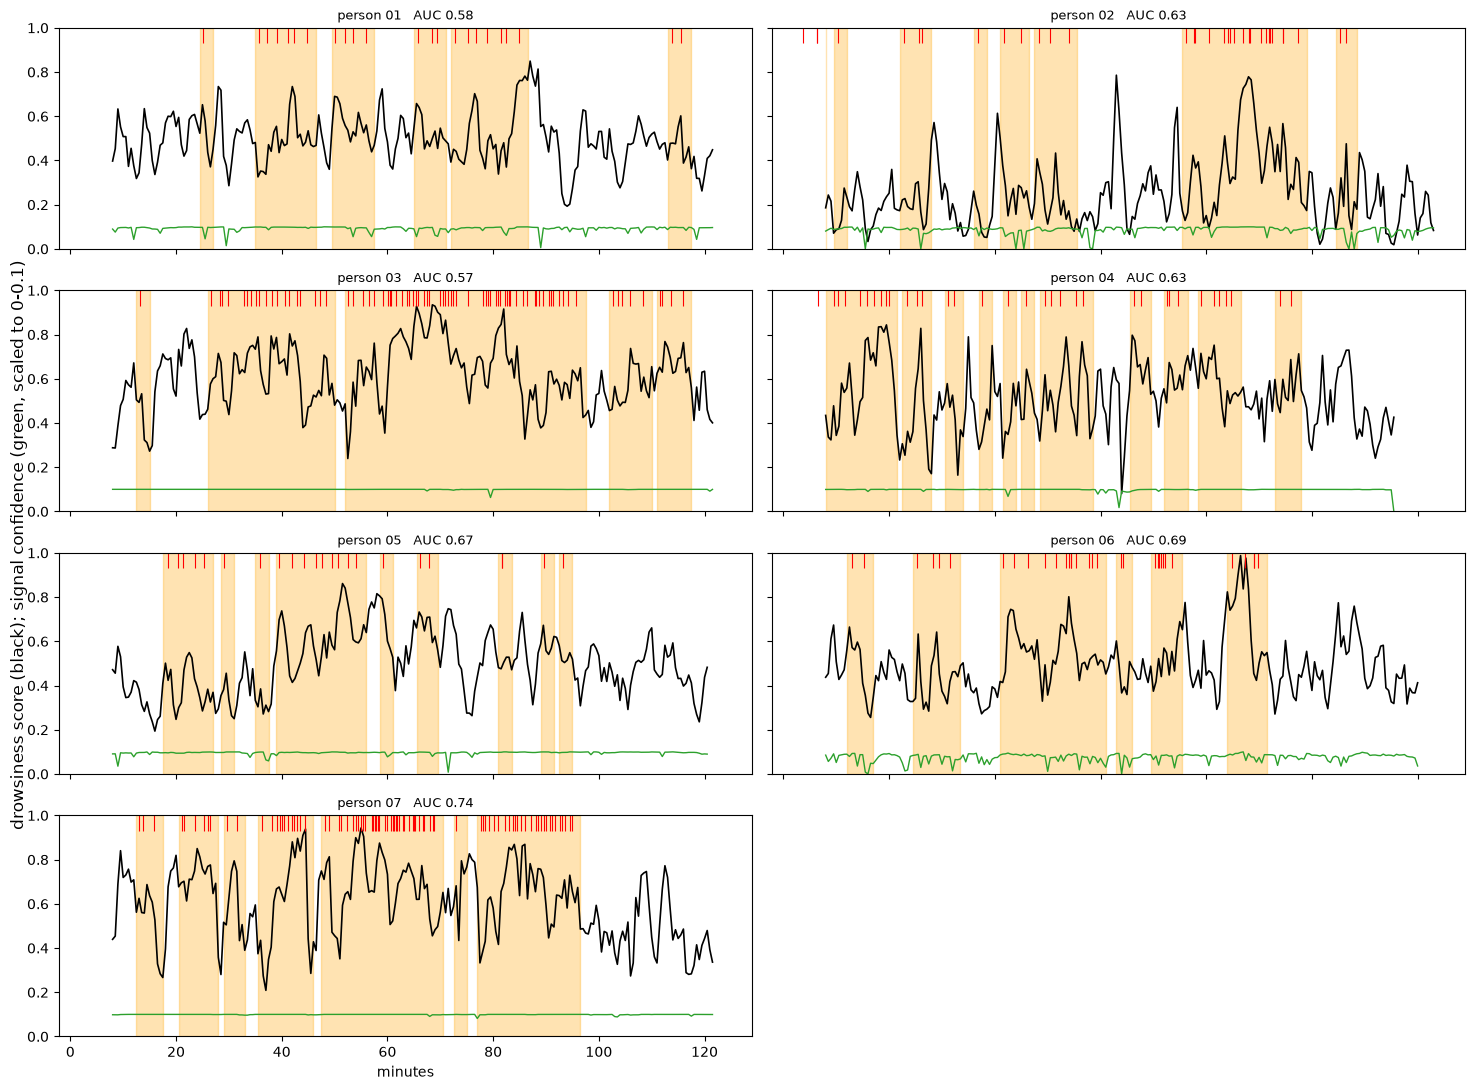

In [19]:
all_scores = {}
for person in labelled.subj.unique():
    model = fit(labelled[labelled.subj != person])
    sub = table[table.subj == person].copy()
    sub["score"] = [model.score(r) for _, r in sub.iterrows()]
    all_scores[person] = sub
fig, axes = plt.subplots(4, 2, figsize=(15, 11), sharex=True, sharey=True)
for ax, (person, sub) in zip(axes.flat, all_scores.items()):
    name = sub.rec.iloc[0]; press = eye[name][1]
    ax.fill_between(sub.t_end / 60, 0, 1, where=(sub.label == 1), color="orange", alpha=0.3, step="mid")
    ax.plot(sub.t_end / 60, sub.score, "k", lw=1.2); ax.plot(sub.t_end / 60, sub.confidence * 0.1, color="tab:green", lw=1)
    ax.vlines(press / 60, 0.93, 1.0, color="r", lw=0.8); ax.set_title(f"person {person}   AUC {per_person[person]['AUC']:.2f}", fontsize=9)
    ax.set_ylim(0, 1)
axes.flat[-1].axis("off")
for ax in axes[-1]:
    ax.set_xlabel("minutes")
fig.supylabel("drowsiness score (black); signal confidence (green, scaled to 0-0.1)")
plt.tight_layout(); plt.show()

In [20]:
final_model = fit(labelled)
final_model.info = {"auc_unseen_people_mean": float(aucs.mean()), "auc_unseen_people_std": float(aucs.std()), "trained_on": "DD-Database trial 1, subjects 1-7, EOG (LOC-ROC)",
                    "window_s": WINDOW_S, "baseline_s": BASELINE_S, "features": FEATURES}
final_model.save(MODEL_PATH)
print("saved", MODEL_PATH)
display(pd.DataFrame({"weight (per standard deviation of the feature)": final_model.coef}, index=FEATURES).round(2))

saved models/eog_drowsiness_model.json


,weight (per standard deviation of the feature)
rate,-0.29
width,0.76
share,-0.57
ivcv,-0.06


**What the results say (honestly)**
* On people the model has never seen, the score separates "drowsy" from "alert" **better than chance but not strongly**: AUC about 0.65 on average, between 0.57 and 0.74 depending on the person. At the cut-off 0.5 it catches about 60% of the drowsy windows and clears about 67% of the alert ones. It is a **trend indicator** (the black lines rise around the button presses for most people), not a reliable alarm on its own.
* **Reading the weights.** `share` = `rate` x `width`, so the weights cannot be read one at a time. Together they say: relative to the person's own start, **fewer eye events and less time spent inside them mean more drowsy**, with longer individual events partly compensating.
* Why it is not better: only 7 people; the labels are self-reported button presses; one sensor type; and only blink-style features. The EEG (separate notebook, later) is likely to add information.
* Because of this the branch should get a **low trust weight** in the fusion until it has been tested on the college sensor; the mean AUC is saved with the model (`info`) so the fusion can read it.
* **Not claimed:** anything about EMG accuracy. That needs real EMG data (`EOG_Detection.ipynb`, Part B).
* The model file is saved by the cell above; `EOG_Detection.ipynb` loads it.